# NumCompute-Stream

In [1]:
from pathlib import Path
import json
import runpy
import sys

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "numcompute_stream").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "numcompute_stream").is_dir()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from numcompute_stream import (
    DecisionTreeClassifier, MixedPreprocessor, Pipeline, StreamTrainer,
    StreamingStats, iter_chunks, load_csv, plot_metric_over_time,
    compare_models, plot_predictions_vs_ground_truth,
)

DATA_PATH = ROOT / "demo" / "data" / "stream_data.csv"
CHUNK_SIZE = 100
BUFFER_SIZE = 300


## Load the CSV through the package

In [2]:
X, y = load_csv(
    DATA_PATH,
    target_column="target",
    categorical_columns=("device",),
    target_dtype=int,
)
print("Features:", X.shape, "Target:", y.shape)
print("Numeric missing counts:", np.isnan(np.asarray(X[:, :3], dtype=float)).sum(axis=0))
print("Classes and counts:", np.unique(y, return_counts=True))
print("First three rows:")
print(X[:3])


Features: (2400, 4) Target: (2400,)
Numeric missing counts: [ 99  88 104]
Classes and counts: (array([0, 1]), array([1187, 1213]))
First three rows:
[[0.3047170798 -1.039984106 0.7504511958 'mobile']
 [0.9405647164 -1.951035189 -1.302179507 'desktop']
 [0.1278404032 -0.3162425923 nan 'desktop']]


## Configure the pipeline

In [3]:
def build_pipeline(buffer_size):
    return Pipeline([
        ("prepare", MixedPreprocessor(categorical_columns=(3,), scale=True)),
        ("tree", DecisionTreeClassifier(
            max_depth=5, buffer_size=buffer_size, random_state=42,
        )),
    ])

example = build_pipeline(BUFFER_SIZE)
example.partial_fit(X[:CHUNK_SIZE], y[:CHUNK_SIZE])
print("Pending after one partial_fit:", example.pending_samples_)
print("Model ready:", example.is_fitted_)


Pending after one partial_fit: 100
Model ready: False


## Process the stream

In [4]:
pipeline = build_pipeline(BUFFER_SIZE)
trainer = StreamTrainer(pipeline, window_size=500)
numeric_stats = StreamingStats(window_size=500)

for X_chunk, y_chunk in iter_chunks(X, y, CHUNK_SIZE):
    numeric_stats.update_stats(np.asarray(X_chunk[:, :3], dtype=float))
    trainer.process_chunk(X_chunk, y_chunk)

print("Chunks:", len(trainer.logs_))
print("Retrains:", pipeline.n_retrains_)
print("Pending:", pipeline.pending_samples_)
print("Evaluated samples:", trainer.metrics.result()["samples"])
assert trainer.metrics.result()["samples"] == len(y) - BUFFER_SIZE


Chunks: 24
Retrains: 8
Pending: 0
Evaluated samples: 2100


In [5]:
print("chunk  warmup  retrained  pending  accuracy  cumulative  train_ms  state_KiB")
for record in trainer.logs_[:6] + trainer.logs_[-3:]:
    print(
        f"{record['chunk']:5d}  {str(record['warmup']):6s}  "
        f"{str(record['retrained']):9s}  {record['pending_samples']:7d}  "
        f"{record['accuracy']:8.3f}  {record['cumulative_accuracy']:10.3f}  "
        f"{1000 * record['training_seconds']:8.2f}  "
        f"{record['memory_bytes'] / 1024:9.1f}"
    )


chunk  warmup  retrained  pending  accuracy  cumulative  train_ms  state_KiB
    1  True    False          100       nan         nan      0.44       17.6
    2  True    False          200       nan         nan      0.46       21.7
    3  True    True             0       nan         nan    261.41       27.2
    4  False   False          100     0.800       0.800      0.35       38.1
    5  False   False          200     0.820       0.810      0.48       48.5
    6  False   True             0     0.770       0.797      7.49       48.1
   22  False   False          100     0.860       0.747      0.34       89.0
   23  False   False          200     0.920       0.756      0.32       95.0
   24  False   True             0     0.830       0.760      5.77       88.9


## Metrics over time

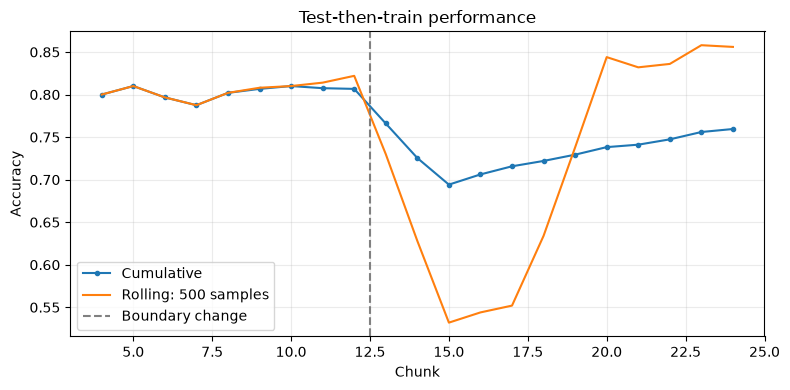

In [6]:
cumulative = [record["cumulative_accuracy"] for record in trainer.logs_]
rolling = [record["rolling_accuracy"] for record in trainer.logs_]
ax = plot_metric_over_time(cumulative, "Test-then-train performance", "Accuracy")
ax.lines[0].set_label("Cumulative")
ax.plot(np.arange(1, len(rolling) + 1), rolling, label="Rolling: 500 samples")
ax.axvline(len(y) // 2 / CHUNK_SIZE + 0.5, color="grey", linestyle="--", label="Boundary change")
ax.legend()
plt.show()


In [7]:
result = trainer.metrics.result()
for name in ("accuracy", "precision", "recall", "f1", "auc"):
    print(f"{name}: {result[name]:.4f}")
print("Confusion-matrix label order:", result["labels"])
print(result["confusion_matrix"])
print("Rolling numeric means:", numeric_stats.result()["mean"])
print("Rolling numeric medians:", numeric_stats.result()["quantiles"][1])


accuracy: 0.7595
precision: 0.7596
recall: 0.7595
f1: 0.7595
auc: 0.7860
Confusion-matrix label order: [0 1]
[[790 258]
 [247 805]]
Rolling numeric means: [0.04142083 0.04661248 0.03525052]
Rolling numeric medians: [ 0.01553731 -0.0250109  -0.00319458]


## Compare buffer sizes

In [8]:
benchmark = runpy.run_path(str(ROOT / "benchmark" / "benchmark_stream.py"))
comparisons = {}
for size in (100, 300, 600):
    model_trainer, summary = benchmark["run_stream"](
        X, y, buffer_size=size, chunk_size=CHUNK_SIZE, common_start=600,
    )
    comparisons[size] = (model_trainer, summary)
    print(
        f"buffer={size}: common_accuracy={summary['common_accuracy']:.4f}, "
        f"common_n={summary['common_evaluated_samples']}, "
        f"retrains={summary['retraining_events']}, "
        f"training_ms={1000 * summary['training_seconds']:.2f}"
    )


buffer=100: common_accuracy=0.7894, common_n=1800, retrains=24, training_ms=83.84


buffer=300: common_accuracy=0.7533, common_n=1800, retrains=8, training_ms=52.25
buffer=600: common_accuracy=0.6550, common_n=1800, retrains=4, training_ms=39.28


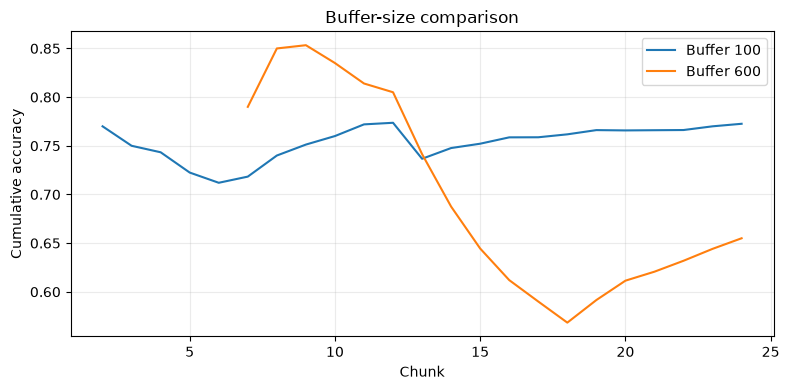

In [9]:
small = [row["cumulative_accuracy"] for row in comparisons[100][0].logs_]
large = [row["cumulative_accuracy"] for row in comparisons[600][0].logs_]
compare_models(small, large, labels=("Buffer 100", "Buffer 600"))
plt.show()


## Inspect predictions from the latest evaluated chunk

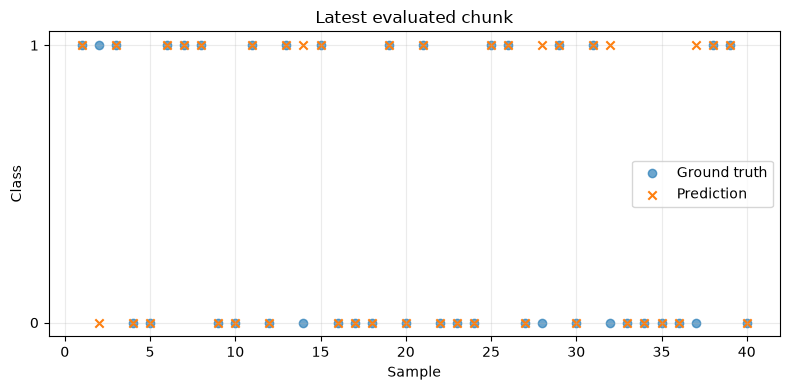

true: [1 1 1 0 0 1 1 1 0 0 1 0 1 0 1 0 0 0 1 0]
pred: [1 0 1 0 0 1 1 1 0 0 1 0 1 1 1 0 0 0 1 0]


In [10]:
plot_predictions_vs_ground_truth(
    trainer.last_y_true_[:40], trainer.last_y_pred_[:40]
)
plt.show()
print("true:", trainer.last_y_true_[:20])
print("pred:", trainer.last_y_pred_[:20])


## Loop versus vectorised split search

In [11]:
vectorisation = benchmark["benchmark_vectorisation"](repeats=3)
assert vectorisation["same_result"]
print(f"Loop median: {1000 * vectorisation['loop_seconds']:.3f} ms")
print(f"Vectorised median: {1000 * vectorisation['vectorised_seconds']:.3f} ms")
print(f"Speedup: {vectorisation['speedup']:.2f}x")

saved_path = ROOT / "benchmark" / "results_stream.json"
if saved_path.stat().st_size:
    saved_results = json.loads(saved_path.read_text(encoding="utf-8"))
    print("Saved benchmark environment:", saved_results["environment"])


Loop median: 128.119 ms
Vectorised median: 0.613 ms
Speedup: 208.93x
Saved benchmark environment: {'python': '3.14.6', 'numpy': '2.5.4', 'platform': 'Windows-11-10.0.26200-SP0'}
